# 📊 01. Exploratory Data Analysis (EDA) - IPO Listing-Gain Predictor

**Project**: IPO Listing-Gain Predictor (Indian Equity Market)  
**Academic Context**: College ML Mini Project (Educational use only, not financial advice)  
**Objective**: Explore the distribution of listing-day gains, relationship with subscription metrics, market mood, sector performance, and missingness patterns to prepare for **Expectation-Maximization (EM) Imputation** and downstream modeling.

---
### EDA Agenda:
1. **Dataset Overview & Schema Inspection**
2. **Missing-Value Report** (Justification for EM Algorithm Imputation)
3. **Distribution of Listing Gain %** (Skewness, Outliers, Classification Targets)
4. **Subscription Metrics vs Listing Gain %** (Log-scale analysis of QIB, NII, Retail demand)
5. **Gain by Sector** (Industry-level performance variation)
6. **Feature Correlation Heatmap** (Multicollinearity & key signal discovery)
7. **Export Figures** to `reports/figures/`

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set visual aesthetic styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

# Ensure output directory exists
FIG_DIR = os.path.join("..", "reports", "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print(f"Figures will be saved to: {os.path.abspath(FIG_DIR)}")

Figures will be saved to: D:\Pranav documents\IPOListingGain Predictor\reports\figures


## 1. Load Cleaned IPO Dataset
We load `data/processed/ipo_clean.csv`, which was sanitized, deduplicated, chronologically sorted, and feature-engineered by `src/data_loader.py`.

In [2]:
# Load data (handles path from either notebooks/ dir or project root)
DATA_PATH = os.path.join("..", "data", "processed", "ipo_clean.csv")
if not os.path.exists(DATA_PATH):
    DATA_PATH = os.path.join("data", "processed", "ipo_clean.csv")

df = pd.read_csv(DATA_PATH)
df['listing_date'] = pd.to_datetime(df['listing_date'])

print(f"Loaded {len(df)} records across {df.shape[1]} columns.")
print(f"Date range: {df['listing_date'].min().date()} to {df['listing_date'].max().date()}")
df.head(5)

Loaded 300 records across 21 columns.
Date range: 2021-01-21 to 2024-12-12


,ipo_name,listing_date,sector,issue_size_cr,price_band_upper,issue_price,listing_price,qib_sub,nii_sub,retail_sub,...,gmp_last_day,fresh_issue_pct,ofs_pct,revenue_growth_pct,profit_growth_pct,pe_vs_peers,nifty_7d_trend_pct,listing_gain_pct,positive_listing,verdict
0,Tata Renewable Power Ltd,2021-01-21,Automobile,749.69,200.61,200.61,243.13,38.19,51.66,1.86,...,44.83,35.03,64.97,10.62,-7.93,1.29,0.25,21.20,1,Apply
1,Maximus Consumer Care Ltd,2021-01-25,Chemicals,323.24,178.46,178.46,205.81,24.65,38.57,39.82,...,49.38,93.51,6.49,16.01,-2.59,0.71,1.82,15.33,1,Apply
2,Shree Agro Industries Ltd,2021-01-27,Automobile,949.50,1631.32,1631.32,1893.91,29.14,27.79,13.61,...,297.47,24.86,75.14,1.90,2.61,1.04,2.33,16.10,1,Apply
3,Tata Logistics Ltd,2021-01-30,Infrastructure,379.56,406.77,406.77,490.20,10.18,31.37,22.62,...,23.22,98.94,1.06,-2.87,15.12,1.08,-1.19,20.51,1,Apply
4,Kalyan Fintech Solutions Ltd,2021-02-03,Technology,492.06,614.45,614.45,763.24,9.75,40.44,3.08,...,61.08,39.42,60.58,-4.11,-11.54,1.41,0.16,24.22,1,Apply


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 21 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   ipo_name            300 non-null    object        
 1   listing_date        300 non-null    datetime64[ns]
 2   sector              300 non-null    object        
 3   issue_size_cr       300 non-null    float64       
 4   price_band_upper    300 non-null    float64       
 5   issue_price         300 non-null    float64       
 6   listing_price       300 non-null    float64       
 7   qib_sub             300 non-null    float64       
 8   nii_sub             300 non-null    float64       
 9   retail_sub          300 non-null    float64       
 10  total_sub           300 non-null    float64       
 11  gmp_last_day        255 non-null    float64       
 12  fresh_issue_pct     300 non-null    float64       
 13  ofs_pct             300 non-null    float64       

## 2. Missing-Value Report & EM Imputation Rationale

In the Indian IPO ecosystem, certain fundamental metrics (e.g., P/E ratio for loss-making new-age tech companies, historical growth rates, unquoted Grey Market Premiums) are legitimately unobserved.
Instead of crude mean/median replacement or discarding valuable IPO rows, we will implement the **Expectation-Maximization (EM) algorithm** to impute missing values by modeling the underlying joint distribution.

Features requiring Imputation:
                    Missing Count  Missing Percentage (%)
profit_growth_pct              55                   18.33
gmp_last_day                   45                   15.00
pe_vs_peers                    30                   10.00
revenue_growth_pct             24                    8.00


Saved figure -> ..\reports\figures\05_missing_values_report.png


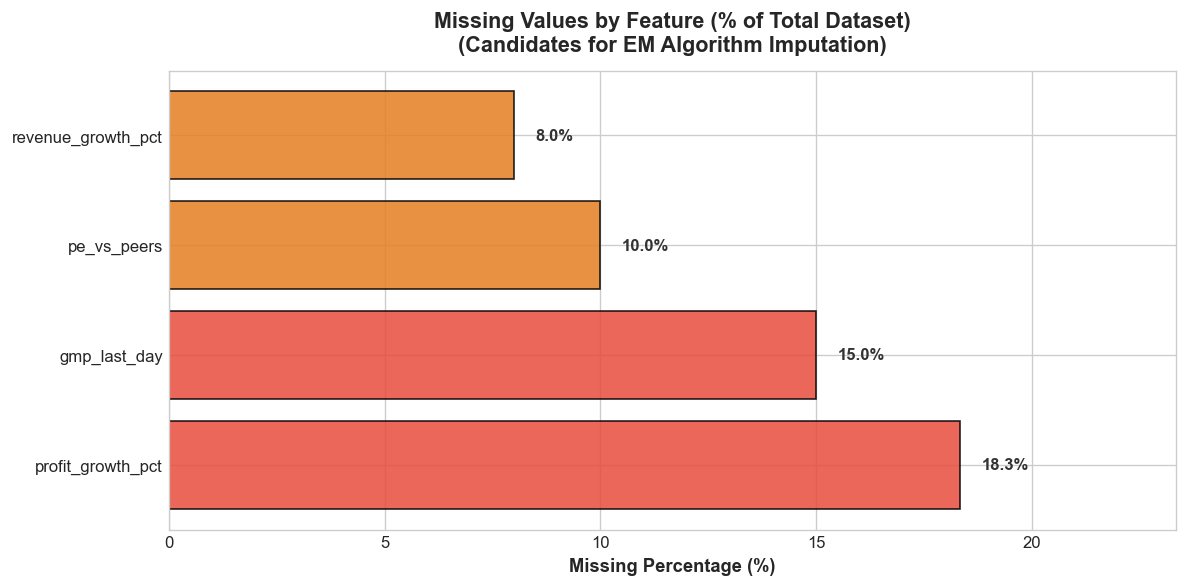

In [4]:
# Compute missing values summary
missing_counts = df.isnull().sum()
missing_pcts = (missing_counts / len(df)) * 100
missing_df = pd.DataFrame({
    'Missing Count': missing_counts,
    'Missing Percentage (%)': missing_pcts.round(2)
}).sort_values(by='Missing Count', ascending=False)

missing_df_active = missing_df[missing_df['Missing Count'] > 0]
print("Features requiring Imputation:")
print(missing_df_active)

# Visualization: Missing Value Barplot
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['#e74c3c' if pct > 10 else '#e67e22' for pct in missing_df_active['Missing Percentage (%)']]
bars = ax.barh(missing_df_active.index, missing_df_active['Missing Percentage (%)'], color=colors, edgecolor='black', alpha=0.85)

ax.set_title("Missing Values by Feature (% of Total Dataset)\n(Candidates for EM Algorithm Imputation)", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Missing Percentage (%)", fontsize=11, fontweight='semibold')
ax.set_xlim(0, max(missing_df_active['Missing Percentage (%)']) + 5)

for bar in bars:
    w = bar.get_width()
    ax.text(w + 0.5, bar.get_y() + bar.get_height() / 2, f"{w:.1f}%", va='center', fontsize=10, fontweight='bold', color='#333333')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "05_missing_values_report.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 3. Distribution of Listing Gain (%) & Verdict Breakdown

Here we explore the primary regression target (`listing_gain_pct`) and its classification groupings:
- **Avoid**: Gain < 0% (discount on debut)
- **Neutral**: Gain between 0% and 15% (modest listing)
- **Apply**: Gain > 15% (strong listing pop)

Saved figure -> ..\reports\figures\01_listing_gain_distribution.png


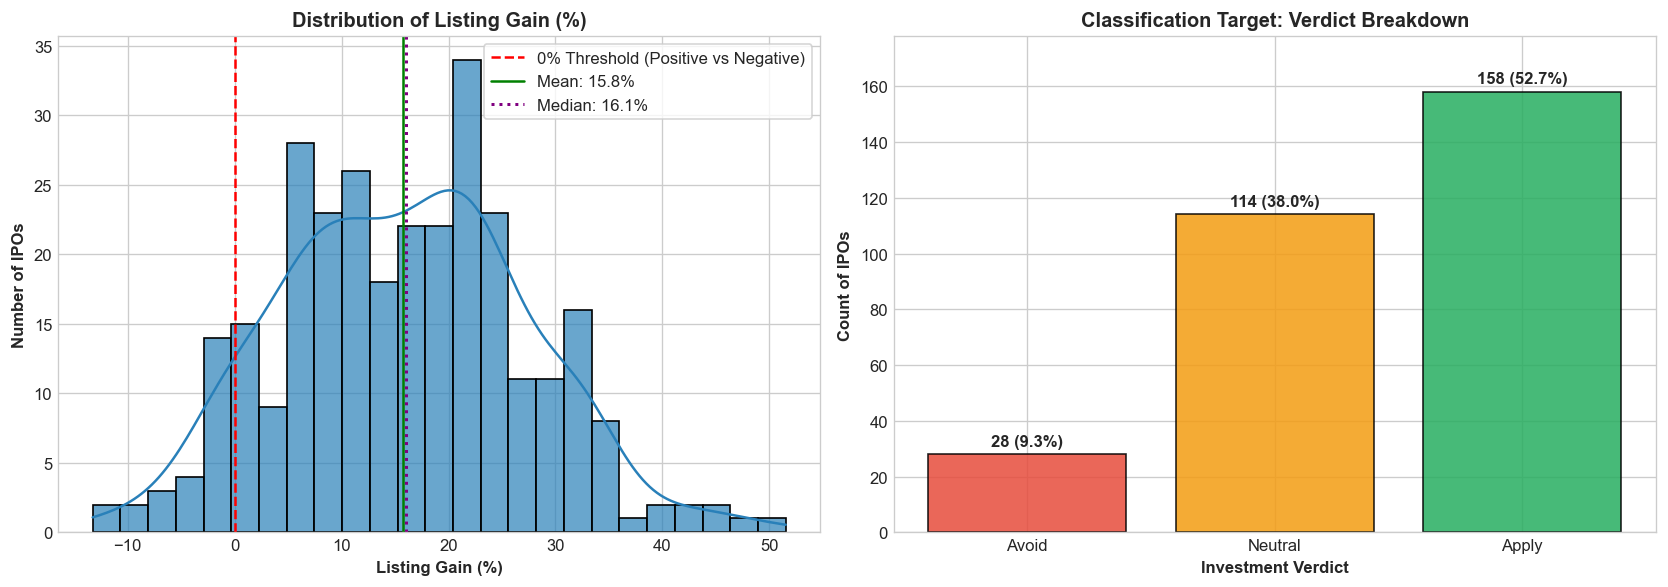

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: Distribution Histogram + KDE
sns.histplot(df['listing_gain_pct'], kde=True, ax=axes[0], color='#2980b9', bins=25, edgecolor='black', alpha=0.7)
mean_gain = df['listing_gain_pct'].mean()
median_gain = df['listing_gain_pct'].median()
axes[0].axvline(0, color='red', linestyle='--', linewidth=1.5, label='0% Threshold (Positive vs Negative)')
axes[0].axvline(mean_gain, color='green', linestyle='-', linewidth=1.5, label=f'Mean: {mean_gain:.1f}%')
axes[0].axvline(median_gain, color='purple', linestyle=':', linewidth=1.8, label=f'Median: {median_gain:.1f}%')

axes[0].set_title("Distribution of Listing Gain (%)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Listing Gain (%)", fontsize=10, fontweight='semibold')
axes[0].set_ylabel("Number of IPOs", fontsize=10, fontweight='semibold')
axes[0].legend(frameon=True)

# Subplot 2: Categorical Verdict Distribution
verdict_order = ['Avoid', 'Neutral', 'Apply']
verdict_colors = {'Avoid': '#e74c3c', 'Neutral': '#f39c12', 'Apply': '#27ae60'}
verdict_counts = df['verdict'].value_counts().reindex(verdict_order)

bars = axes[1].bar(verdict_order, verdict_counts.values, color=[verdict_colors[v] for v in verdict_order], edgecolor='black', alpha=0.85)
axes[1].set_title("Classification Target: Verdict Breakdown", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Investment Verdict", fontsize=10, fontweight='semibold')
axes[1].set_ylabel("Count of IPOs", fontsize=10, fontweight='semibold')

for bar in bars:
    h = bar.get_height()
    pct = (h / len(df)) * 100
    axes[1].text(bar.get_x() + bar.get_width() / 2, h + 3, f"{h} ({pct:.1f}%)", ha='center', fontsize=10, fontweight='bold')

axes[1].set_ylim(0, max(verdict_counts.values) + 20)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "01_listing_gain_distribution.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 4. Subscription vs Listing Gain % (Log-Scale Analysis)

In the Indian IPO market, subscription multiples (especially institutional QIB and total subscriptions) often exhibit heavy right-skew (spanning from 0.5x to 200x+). We plot subscription vs listing gain on a **log-scale** x-axis to reveal the underlying power-law relationship.

Saved figure -> ..\reports\figures\02_subscription_vs_gain.png


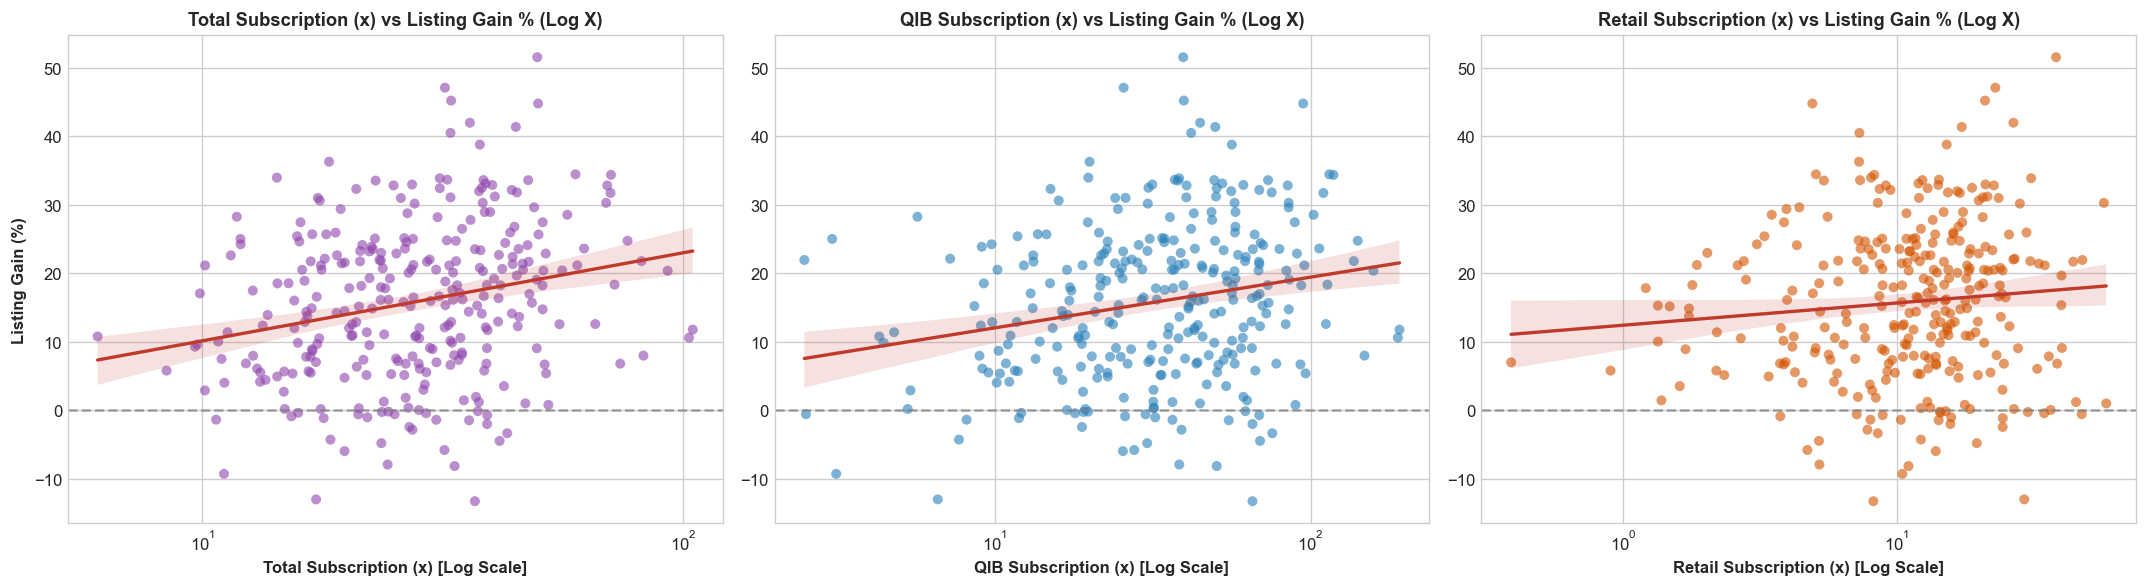

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sub_cols = [
    ('total_sub', 'Total Subscription (x)', '#8e44ad'),
    ('qib_sub', 'QIB Subscription (x)', '#2980b9'),
    ('retail_sub', 'Retail Subscription (x)', '#d35400')
]

for idx, (col, label, color) in enumerate(sub_cols):
    ax = axes[idx]
    sns.regplot(
        data=df,
        x=col,
        y='listing_gain_pct',
        ax=ax,
        scatter_kws={'alpha': 0.6, 'color': color, 'edgecolor': 'none'},
        line_kws={'color': '#c0392b', 'linewidth': 2},
        logx=True
    )
    ax.set_xscale('log')
    ax.axhline(0, color='gray', linestyle='--', alpha=0.7)
    ax.set_title(f"{label} vs Listing Gain % (Log X)", fontsize=11, fontweight='bold')
    ax.set_xlabel(f"{label} [Log Scale]", fontsize=10, fontweight='semibold')
    ax.set_ylabel("Listing Gain (%)" if idx == 0 else "", fontsize=10, fontweight='semibold')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "02_subscription_vs_gain.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 5. Listing Gain by Sector

Different industries experience distinct investor appetite, regulatory cycles, and valuation multiples. This visualization highlights sector-specific median listing returns and dispersion.

C:\Users\Lenovo\AppData\Local\Temp\ipykernel_3792\1274980774.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(


Saved figure -> ..\reports\figures\04_gain_by_sector.png


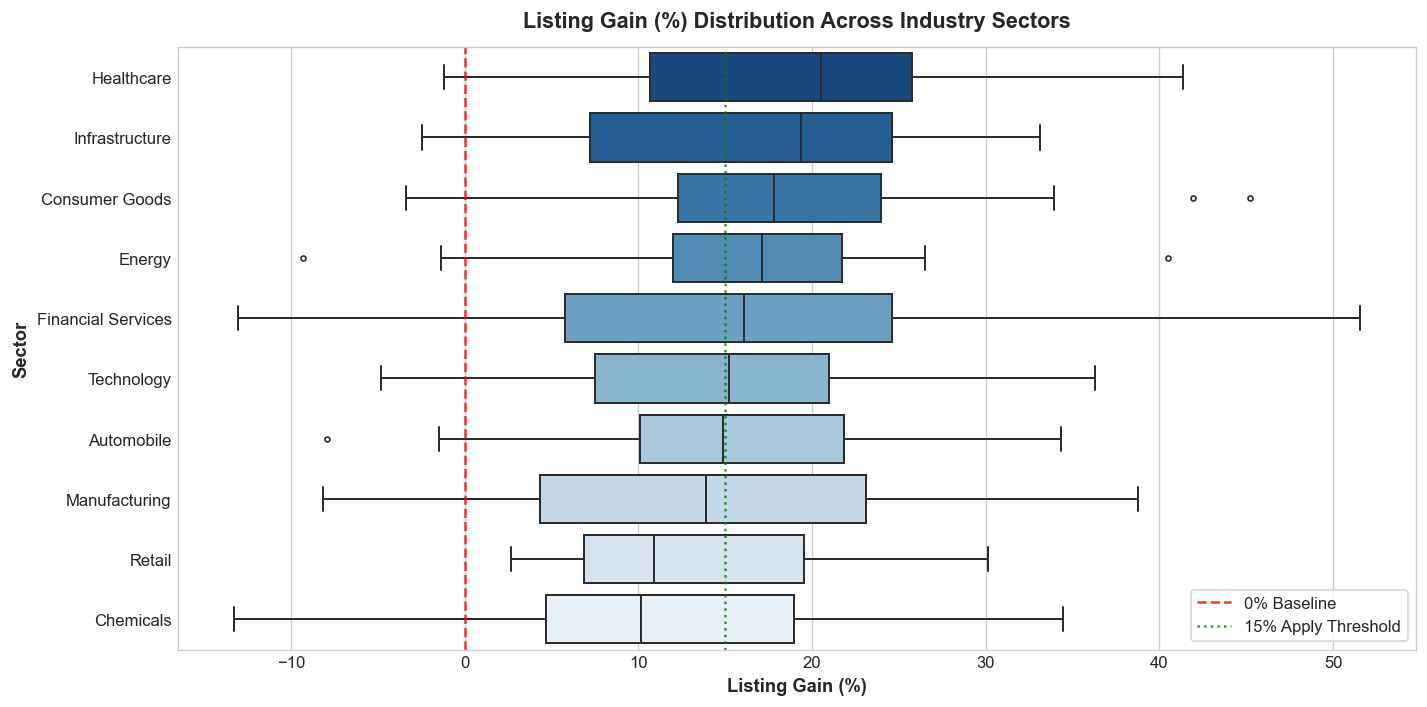

In [7]:
# Sort sectors by median listing gain
sector_order = df.groupby('sector')['listing_gain_pct'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 6))
sns.boxplot(
    data=df,
    x='listing_gain_pct',
    y='sector',
    order=sector_order,
    palette='Blues_r',
    ax=ax,
    fliersize=3,
    linewidth=1.2
)

ax.axvline(0, color='red', linestyle='--', linewidth=1.5, alpha=0.8, label='0% Baseline')
ax.axvline(15, color='green', linestyle=':', linewidth=1.5, alpha=0.8, label='15% Apply Threshold')

ax.set_title("Listing Gain (%) Distribution Across Industry Sectors", fontsize=13, fontweight='bold', pad=12)
ax.set_xlabel("Listing Gain (%)", fontsize=11, fontweight='semibold')
ax.set_ylabel("Sector", fontsize=11, fontweight='semibold')
ax.legend(loc='lower right', frameon=True)

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "04_gain_by_sector.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 6. Correlation Heatmap of Numeric Features

We compute the Pearson correlation matrix to understand interactions between issue characteristics, subscriptions, financial health, macro conditions (Nifty trend), and the listing pop.

Saved figure -> ..\reports\figures\03_correlation_heatmap.png


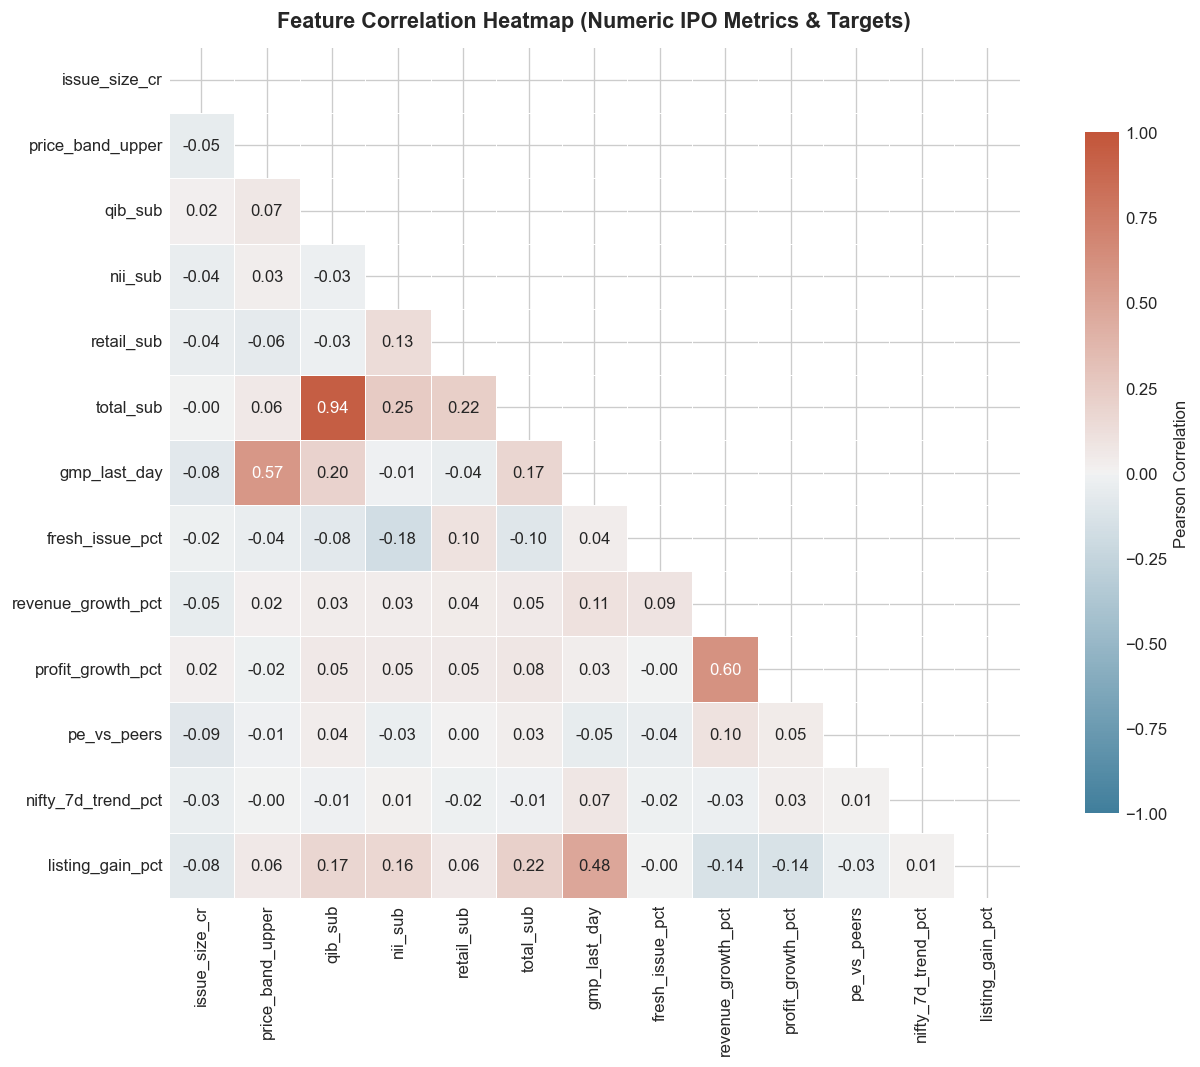

In [8]:
numeric_cols = [
    'issue_size_cr', 'price_band_upper', 'qib_sub', 'nii_sub', 'retail_sub',
    'total_sub', 'gmp_last_day', 'fresh_issue_pct', 'revenue_growth_pct',
    'profit_growth_pct', 'pe_vs_peers', 'nifty_7d_trend_pct', 'listing_gain_pct'
]

corr = df[numeric_cols].corr()

fig, ax = plt.subplots(figsize=(12, 9))
mask = np.triu(np.ones_like(corr, dtype=bool))
cmap = sns.diverging_palette(230, 20, as_cmap=True)

sns.heatmap(
    corr,
    mask=mask,
    cmap=cmap,
    vmax=1.0,
    vmin=-1.0,
    center=0,
    annot=True,
    fmt=".2f",
    square=True,
    linewidths=0.6,
    cbar_kws={"shrink": 0.8, "label": "Pearson Correlation"},
    ax=ax
)

ax.set_title("Feature Correlation Heatmap (Numeric IPO Metrics & Targets)", fontsize=13, fontweight='bold', pad=12)
plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "03_correlation_heatmap.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 7. Key Findings & Pipeline Next Steps

### 🔍 Key Insights from EDA:
1. **Subscription as Lead Signal**: Total subscription and QIB demand show a strong positive non-linear relationship with listing gain, confirming log-transformation and non-linear models (Polynomial Regression, Gradient Boosting) will be impactful.
2. **Missingness in Financials & GMP**: `profit_growth_pct` (~18%), `gmp_last_day` (~15%), and `pe_vs_peers` (~10%) have missing entries. Our **Expectation-Maximization (EM)** algorithm is essential to recover this joint distribution without inducing bias.
3. **Sector Clustering Potential**: Clear clustering in returns across high-momentum sectors (Technology, Consumer) vs cyclical capital goods, confirming that **K-Means / K-Medoids** can identify genuine peer IPOs.
4. **Market Momentum**: Positive correlation between `nifty_7d_trend_pct` and debut pop supports our planned **Hidden Markov Model (HMM)** to detect Cold/Warm/Hot market regimes.

### ⏭️ Next Actions:
- Run `src/split.py` to establish strict chronological train/test boundaries.
- Implement EM Imputation fitted on the train split only.
- Implement custom NumPy Hidden Markov Model (HMM) for market mood classification.